# Plot results of parameter sweeps for Context Identification task with both outputs

The purpose of this notebook is to plot some analyses of the results of a hyperparameter sweep performed on the `ContextIdentification` task when the model was tasked to give both outputs. The parameters were:

1. Seed
2. Gamma
3. Attention mechanism

## Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

import seaborn as sns

## Unsigned models

### Convert JSON to DataFrame

In [2]:
with open("../data/partial_relational_sweep.json", "r") as f:
    results = json.load(f)

In [3]:
def load_results(json_path):
    """Load results from JSON file."""
    with open(json_path, 'r') as f:
        return json.load(f)

In [4]:
rows = []
for attn_kind, d2 in results.items():
    for gamma_str, d3 in d2.items():
        gamma = float(gamma_str)
        for seed_str, hist in d3.items():
            seed = int(seed_str)

            # history lists
            train_acc_f  = np.array(hist["train_acc_f"], dtype=float)
            test_acc_f   = np.array(hist["test_acc_f"], dtype=float)
            train_acc_p  = np.array(hist["train_acc_p"], dtype=float)
            test_acc_p   = np.array(hist["test_acc_p"], dtype=float)

            rows.append({
                "attn_kind": attn_kind,
                "gamma": gamma,
                "seed": seed,

                "epochs": len(train_acc_f),

                "final_train_acc_feature":  train_acc_f[-1],
                "final_test_acc_feature":  test_acc_f[-1],
                "final_train_acc_position":  train_acc_p[-1],
                "final_test_acc_position":  test_acc_p[-1],

                # optional: best epoch metrics
                "best_test_acc_feature":  float(test_acc_f.max()),
                "best_test_acc_position":  float(test_acc_p.max()),
            })

In [5]:
df = pd.DataFrame(rows)
df.head()

,attn_kind,gamma,seed,epochs,final_train_acc_feature,final_test_acc_feature,final_train_acc_position,final_test_acc_position,best_test_acc_feature,best_test_acc_position
0,linear,0.0,0,2500,0.976,0.900,0.158,0.094,0.926,0.126
1,linear,0.0,1,2500,0.982,0.898,0.188,0.088,0.926,0.116
2,linear,0.0,2,2500,0.984,0.868,0.154,0.084,0.896,0.138
3,linear,0.0,3,2500,0.976,0.878,0.168,0.074,0.898,0.114
4,linear,0.0,4,2500,0.974,0.904,0.196,0.130,0.918,0.152


### Test accuracy heatmap

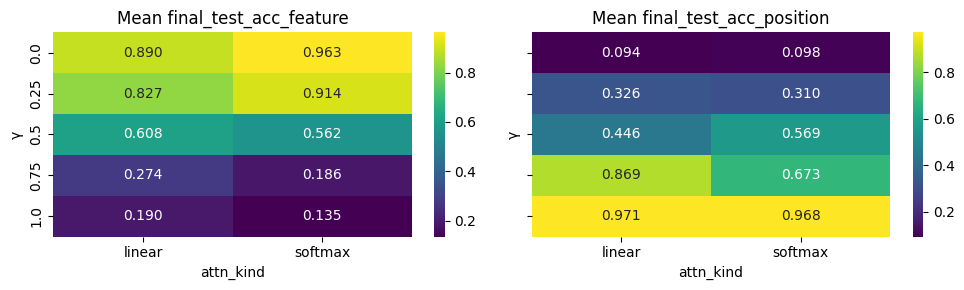

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

for ax, acc in zip(axes, ["final_test_acc_feature", "final_test_acc_position"]):
    pivot = (
        df
        .groupby(["gamma", "attn_kind"])[acc]
        .mean()
        .reset_index()
        .pivot(index="gamma", columns="attn_kind", values=acc)
        .sort_index()
    )

    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="viridis")
    ax.set_title(f"Mean {acc}")
    ax.set_xlabel("attn_kind")
    ax.set_ylabel("γ")

plt.tight_layout()
plt.show()

## Test accuracy curves

In [7]:
def extract_test_acc_trajectories(results, attn_kind, gamma):
    """Extract test accuracy trajectories across seeds.

    Args:
        results: nested dict from sweep
        attn_kind: 'linear' or 'softmax'
        gamma: gamma value

    Returns:
        test_acc_f: (num_seeds, num_epochs) feature accuracies
        test_acc_p: (num_seeds, num_epochs) position accuracies
    """
    gamma_key = str(float(gamma))
    seed_data = results[attn_kind][gamma_key]

    trajectories_f = []
    trajectories_p = []
    for seed in sorted(seed_data.keys()):
        history = seed_data[seed]
        trajectories_f.append(np.array(history['test_acc_f']))
        trajectories_p.append(np.array(history['test_acc_p']))

    return np.array(trajectories_f), np.array(trajectories_p)

In [8]:
def plot_averaged_accuracy(
    results_path='./data/partial_relational_sweep.json',
    attn_kind='softmax',
    save_path='./results/partial_relational_averaged_accuracy.png',
):
    """Plot average of feature and position accuracies."""
    results = load_results(results_path)

    gammas = [0.0, 0.25, 0.5, 0.75, 1.0]

    # Color map
    cmap = plt.cm.plasma
    colors = [cmap(i / (len(gammas) - 1)) for i in range(len(gammas))]

    fig, ax = plt.subplots(figsize=(8, 5))

    for i, gamma in enumerate(gammas):
        # Extract trajectories
        test_acc_f, test_acc_p = extract_test_acc_trajectories(results, attn_kind, gamma)

        # Average feature and position
        test_acc_avg = (test_acc_f + test_acc_p) / 2.0

        # Compute mean and SEM
        mean_acc = test_acc_avg.mean(axis=0)
        sem_acc = test_acc_avg.std(axis=0) / np.sqrt(test_acc_avg.shape[0])

        epochs = np.arange(len(mean_acc))

        # Plot
        label = f"γ={gamma:.2f}"
        ax.plot(
            epochs,
            mean_acc,
            color=colors[i],
            label=label,
            linewidth=1.5,
            alpha=0.8,
        )
        ax.fill_between(
            epochs,
            mean_acc - sem_acc,
            mean_acc + sem_acc,
            color=colors[i],
            alpha=0.15,
        )

    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Average Test Accuracy', fontsize=12)
    ax.set_ylim(0,1)
    ax.set_title(
        f'Both Feature and Position Task - Averaged Accuracy',
        fontsize=13,
        fontweight='bold'
    )
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=10)

    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved to {save_path}")

    plt.show()

Saved to ../results/partial_relational_averaged_accuracy_softmax.png


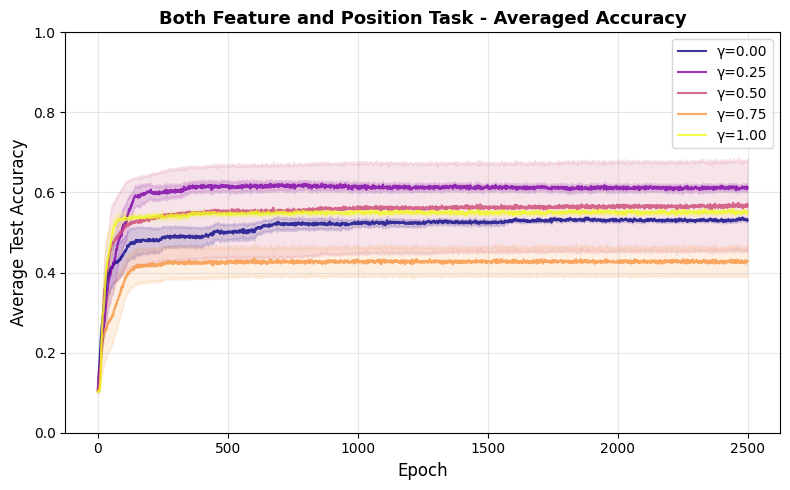

In [9]:
# Plot averaged accuracy
plot_averaged_accuracy(
    results_path='../data/partial_relational_sweep.json',
    attn_kind='softmax',
    save_path='../results/partial_relational_averaged_accuracy_softmax.png',
)

## Signed models

### Convert JSON to DataFrame

In [10]:
with open("../data/partial_relational_sweep_signed.json", "r") as f:
    results = json.load(f)

In [11]:
rows = []
for attn_kind, d2 in results.items():
    for gamma_str, d3 in d2.items():
        gamma = float(gamma_str)
        for seed_str, hist in d3.items():
            seed = int(seed_str)

            # history lists
            train_acc_f  = np.array(hist["train_acc_f"], dtype=float)
            test_acc_f   = np.array(hist["test_acc_f"], dtype=float)
            train_acc_p  = np.array(hist["train_acc_p"], dtype=float)
            test_acc_p   = np.array(hist["test_acc_p"], dtype=float)

            rows.append({
                "attn_kind": attn_kind,
                "gamma": gamma,
                "seed": seed,

                "epochs": len(train_acc_f),

                "final_train_acc_feature":  train_acc_f[-1],
                "final_test_acc_feature":  test_acc_f[-1],
                "final_train_acc_position":  train_acc_p[-1],
                "final_test_acc_position":  test_acc_p[-1],

                # optional: best epoch metrics
                "best_test_acc_feature":  float(test_acc_f.max()),
                "best_test_acc_position":  float(test_acc_p.max()),
            })

In [12]:
df = pd.DataFrame(rows)
df.head()

,attn_kind,gamma,seed,epochs,final_train_acc_feature,final_test_acc_feature,final_train_acc_position,final_test_acc_position,best_test_acc_feature,best_test_acc_position
0,linear,0.0,0,2500,0.952,0.882,0.184,0.086,0.918,0.118
1,linear,0.0,1,2500,0.990,0.890,0.206,0.102,0.914,0.122
2,linear,0.0,2,2500,0.980,0.866,0.182,0.098,0.896,0.140
3,linear,0.0,3,2500,0.980,0.880,0.182,0.076,0.908,0.130
4,linear,0.0,4,2500,0.948,0.858,0.160,0.114,0.882,0.138


### Test accuracy heatmap

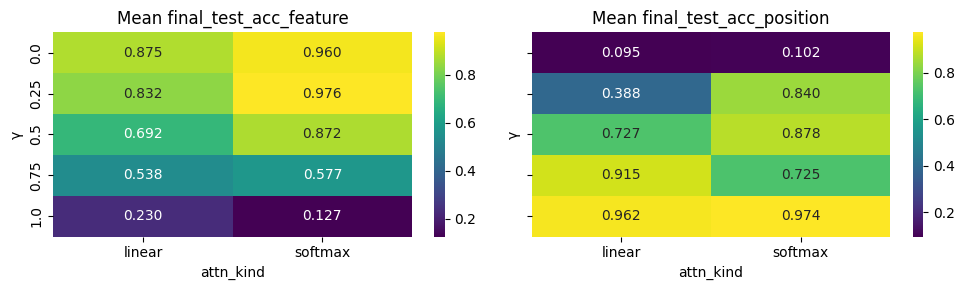

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

for ax, acc in zip(axes, ["final_test_acc_feature", "final_test_acc_position"]):
    pivot = (
        df
        .groupby(["gamma", "attn_kind"])[acc]
        .mean()
        .reset_index()
        .pivot(index="gamma", columns="attn_kind", values=acc)
        .sort_index()
    )

    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="viridis")
    ax.set_title(f"Mean {acc}")
    ax.set_xlabel("attn_kind")
    ax.set_ylabel("γ")

plt.tight_layout()
plt.show()

## Test accuracy history

Saved to ../results/partial_relational_averaged_accuracy_signed.png


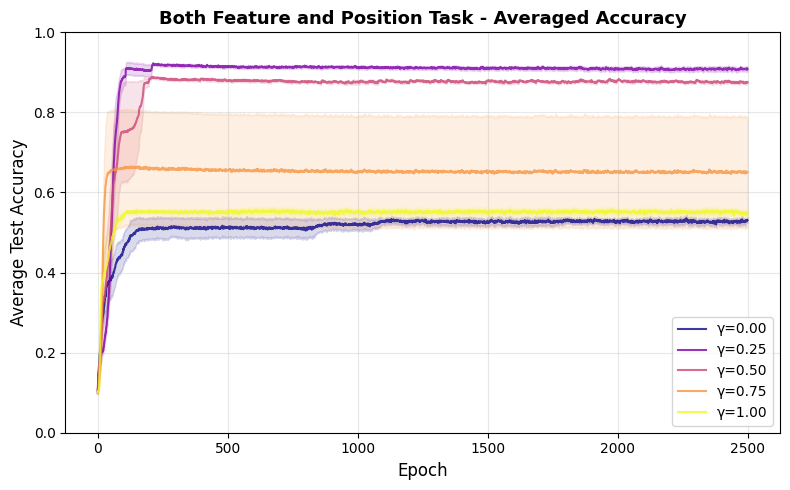

In [14]:
# Plot averaged accuracy
plot_averaged_accuracy(
    results_path='../data/partial_relational_sweep_signed.json',
    attn_kind='softmax',
    save_path='../results/partial_relational_averaged_accuracy_signed.png',
)